# Experiment 4 — Random vs. difficulty-stratified selection, SDD only

Compare configurations produced by the existing evolutionary tree inducer using three randomly selected datasets versus one randomly selected dataset from each difficulty stratum. **No superiority is assumed.** Stratification is across datasets, not class weighting.

This is an exploratory evaluation on **one fixed external reserve**, not evidence about multiple dataset pools. Five paired runs capture joint selection and search variation without separating those sources statistically. The inferential unit is the paired run, never a CV fold.

## 0. Setup and protocol

Default mode: `pilot`. Set `MODE` explicitly to `smoke`, `full_search`, or `final_evaluation` when needed. Running all cells in the default mode launches only the first pair through two generations and never evaluates the reserve.

Both conditions use mu=10, lambda=10, 10 generations, crossover=1.0, mutation=0.1, and exactly five stratified folds. Each full search requests 110 candidates, at most 1,650 search fits before caching/failures. The pilot requests 30 candidates per condition. Cache hits never add candidates or generations. The gene–dataset hard timeout is 900 seconds for all five folds together, not a timeout for a whole gene across all datasets.

The original generator, repair, tournament (k=2), crossover, mutation domains, mu+lambda survival, decoder, pruning, and tree augmentation are retained. The original clamped initial sampling and crossover modulo behavior are also retained explicitly. Equal-fitness survivors/winners use lexicographic genes; no secondary performance objective is introduced.

In [19]:
import os
for variable in ("OMP_NUM_THREADS", "MKL_NUM_THREADS", "OPENBLAS_NUM_THREADS", "NUMEXPR_NUM_THREADS"):
    os.environ[variable] = "1"

import sys
import json
import subprocess
from pathlib import Path
import pandas as pd
from IPython.display import display, Image

MODE = "final_evaluation"
N_WORKERS = 4
GEN_DATASET_TIMEOUT_S = 900
PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
                    if (p / "evolution" / "random_vs_stratified_sdd.py").exists())
RESULTS = PROJECT_ROOT / "results" / "random_vs_stratified_sdd"
ENTRY = PROJECT_ROOT / "experiments" / "run_random_vs_stratified_sdd.py"
# Override SDD_PYTHON to select another installed environment; no packages are installed here.
candidates = [os.environ.get("SDD_PYTHON"), sys.executable,
              str(Path(sys.executable).parent / "envs" / "EvoML" / "python.exe")]
PYTHON = None
for candidate in dict.fromkeys(p for p in candidates if p):
    if Path(candidate).exists():
        probe = subprocess.run([candidate, "-c", "import numpy,pandas,scipy,sklearn,pymoo,matplotlib"],
                               cwd=PROJECT_ROOT, capture_output=True, text=True)
        if probe.returncode == 0:
            PYTHON = candidate
            break
if PYTHON is None:
    raise RuntimeError("No compatible Python found. Set SDD_PYTHON to an environment with numpy, pandas, scipy, scikit-learn, pymoo and matplotlib.")
if MODE not in {"smoke", "pilot", "full_search", "final_evaluation"}:
    raise ValueError("Unknown mode")

def run_entry(*extra):
    RESULTS.mkdir(parents=True, exist_ok=True)
    command = [PYTHON, "-u", str(ENTRY), "--output", str(RESULTS),
               "--n-workers", str(N_WORKERS), "--gen-dataset-timeout-s", str(GEN_DATASET_TIMEOUT_S), *extra]
    # A proper script entry point is required by multiprocessing spawn on Windows.
    with (RESULTS / "notebook_execution.log").open("a", encoding="utf-8") as log:
        with subprocess.Popen(command, cwd=PROJECT_ROOT, stdout=subprocess.PIPE,
                              stderr=subprocess.STDOUT, text=True, errors="replace") as process:
            for line in process.stdout:
                print(line, end="")
                log.write(line)
                log.flush()
            returncode = process.wait()
    if returncode:
        raise RuntimeError(f"Experiment process exited with {returncode}; inspect notebook_execution.log")

print("Project:", PROJECT_ROOT)
print("Experiment interpreter:", PYTHON)
print("Execution mode:", MODE)
run_entry("--prepare-only")
protocol = json.loads((RESULTS / "protocol.json").read_text())
display(pd.DataFrame([protocol["config"]]))

Project: c:\Users\sarah\OneDrive\Documentos\DCC_Thesis_codes\AutoML_DecisionTrees
Experiment interpreter: c:\Users\sarah\anaconda3\envs\EvoML\python.exe
Execution mode: final_evaluation
Canonical pool: 17 (expected 17); held out: ['anneal', 'banknote', 'cylinder_bands', 'ionosphere', 'iris']; discrepancy: False


,crossover_prob,final_cv_folds,gen_dataset_timeout_s,generations,lambd,mu,mutation_prob,n_workers,search_cv_folds
0,1.0,5,900,10,10,10,0.1,4,5


### Execution status and recovery audit

A successful pilot requires both first-pair searches to reach generation 2 with a valid candidate. A finished process or a passing setup cell does not establish this. The table below reads durable checkpoints; generation 0 means only the initial population was completed. Evaluations written after the last checkpoint can be reused from the complete-result cache, but the unfinished generation must be reconstructed from its saved RNG state.

On 2026-11-03, resumption failed because JSON encoded the same timeout as `900` versus `900.0`. The loader now returns the validated **persisted** protocol representation. The recovery preserved scientific configuration, scores, fitness, population and RNG state; it updated only the reviewed source identity and dependent hashes. Original artifacts and a migration audit are retained under `results/random_vs_stratified_sdd/recovery/2026-11-03_numeric_identity/`. No additional long searches were launched during that repair.

If the pilot is incomplete, use `MODE="pilot"` to finish it and inspect its cost report before selecting `full_search`. The complete search can also resume the same valid checkpoint directly; the timeout and candidate budget remain unchanged.

In [20]:
pilot_status = []
for selection in protocol["selections"][:2]:
    checkpoint = RESULTS / "runs" / selection["run_id"] / "checkpoint.json"
    if checkpoint.exists():
        state = json.loads(checkpoint.read_text())
        done = state["generation"] >= 2 and state["status"] != "failed" and state["best_fitness"] is not None
        pilot_status.append(dict(condition=selection["condition"], status=state["status"],
            last_completed_generation=state["generation"], pilot_complete=done,
            viable_population=sum(value is not None for value in state["fitness"]),
            recorded_generation_minutes=sum(h["seconds"] for h in state["history"]) / 60,
            recorded_timeouts=sum(h["timeouts"] for h in state["history"])))
    else:
        pilot_status.append(dict(condition=selection["condition"], status="not_started",
            last_completed_generation=None, pilot_complete=False,
            viable_population=None, recorded_generation_minutes=0., recorded_timeouts=0))
display(pd.DataFrame(pilot_status))
PILOT_COMPLETE = all(row["pilot_complete"] for row in pilot_status)
print("Both pilot conditions completed:", PILOT_COMPLETE)
if not PILOT_COMPLETE:
    print('The pilot is incomplete. Set MODE="pilot" to finish it before interpreting pilot costs.')

,condition,status,last_completed_generation,pilot_complete,viable_population,recorded_generation_minutes,recorded_timeouts
0,random,complete,10,True,10,225.215796,32
1,stratified,complete,10,True,10,56.104677,0


Both pilot conditions completed: True


## 1. Pool, reserve, and characterization

Reuse the canonical four non-dummy baselines from `New_Characterization_Experiments.ipynb` through their individual JSON results, without executing a notebook or retraining baselines. Validate their complete 15 scores (5 folds × 3 repetitions), original file/filtered-data hashes, target/ID definitions, and metadata. The eligible pool requires at least five observations per class and complete results from all four original baselines. The observed number and identities are exported; a discrepancy is reported rather than forcing 17.

Sort names and sample five datasets uniformly without replacement using `default_rng(2026)`. Save the reserve before selection or search. Only the remaining pool contributes to min–max normalization and grouping: F is the mean of the four baseline means, E=1−F, V is the mean of their within-model sample standard deviations, D=0.70 norm(E)+0.30 norm(V). Sort ascending D, then exact ties by higher F, lower V, name; split with `np.array_split`.

Historical baseline results on reserved datasets establish eligibility only. Their scores do not contribute to normalization, grouping, or selection. Loading raw targets/IDs and precomputing partition manifests are metadata operations, not reserved model evaluation.

In [21]:
reserve = json.loads((RESULTS / "reserve_manifest.json").read_text())
print(json.dumps(reserve, indent=2))
display(pd.read_csv(RESULTS / "reserve_manifest.csv"))
display(pd.read_csv(RESULTS / "available_pool_ranking.csv"))
display(pd.read_csv(RESULTS / "target_id_audit.csv"))
assert not set(reserve["held_out"]) & set(reserve["available"])

{
  "available": [
    "balance_scale",
    "breast_cancer",
    "car",
    "credit_approval",
    "glass",
    "haberman",
    "heart_disease",
    "parkinsons",
    "semeion",
    "sonar",
    "tic_tac_toe",
    "wine_red"
  ],
  "discrepancy": false,
  "eligible": [
    "anneal",
    "balance_scale",
    "banknote",
    "breast_cancer",
    "car",
    "credit_approval",
    "cylinder_bands",
    "glass",
    "haberman",
    "heart_disease",
    "ionosphere",
    "iris",
    "parkinsons",
    "semeion",
    "sonar",
    "tic_tac_toe",
    "wine_red"
  ],
  "exclusions": [
    {
      "dataset": "abalone",
      "reason": "min_class_count=1 < 5"
    },
    {
      "dataset": "arrhythmia",
      "reason": "min_class_count=2 < 5"
    },
    {
      "dataset": "bridges",
      "reason": "min_class_count=1 < 5"
    }
  ],
  "expected_size": 17,
  "held_out": [
    "anneal",
    "banknote",
    "cylinder_bands",
    "ionosphere",
    "iris"
  ],
  "historical_eligible": [
    "anneal",
   

,dataset,role
0,anneal,held_out
1,balance_scale,available
2,banknote,held_out
3,breast_cancer,available
4,car,available
5,credit_approval,available
6,cylinder_bands,held_out
7,glass,available
8,haberman,available
9,heart_disease,available


,dataset,F,V,E,normalized_E,normalized_V,difficulty_score,difficulty_group,position
0,tic_tac_toe,0.947386,0.015383,0.052614,0.003753,0.000000,0.002627,easy,1.0
1,breast_cancer,0.949823,0.019215,0.050177,0.000000,0.056399,0.016920,easy,2.0
2,semeion,0.835588,0.015506,0.164412,0.175893,0.001810,0.123668,easy,3.0
3,car,0.865277,0.032038,0.134723,0.130180,0.245115,0.164660,easy,4.0
4,credit_approval,0.829431,0.036690,0.170569,0.185374,0.313578,0.223835,intermediate,5.0
5,balance_scale,0.655328,0.022737,0.344672,0.453448,0.108220,0.349879,intermediate,6.0
6,parkinsons,0.784356,0.068755,0.215644,0.254778,0.785484,0.413990,intermediate,7.0
7,sonar,0.744293,0.061973,0.255707,0.316464,0.685665,0.427224,intermediate,8.0
8,haberman,0.580712,0.063686,0.419288,0.568337,0.710878,0.611099,hard,9.0
9,glass,0.621593,0.083331,0.378407,0.505391,1.000000,0.653774,hard,10.0


,dataset,target_col,dropped_id_cols,n_samples,n_features,n_classes,n_numeric,n_categorical,n_missing_targets_removed,min_class_count,missing_pct,class_entropy,imbalance_ratio,samples_per_feature
0,abalone,target,NaN,4177,8,28,7,1,0,1,0.000000,3.602007,689.000000,522.125000
1,anneal,target,NaN,798,38,5,16,22,0,8,64.938662,1.190925,76.000000,21.000000
2,arrhythmia,target,NaN,452,279,13,279,0,0,2,0.323532,2.401386,122.500000,1.620072
3,balance_scale,class,NaN,625,4,3,4,0,0,49,0.000000,1.318116,5.877551,156.250000
4,banknote,4,NaN,1372,4,2,4,0,0,610,0.000000,0.991128,1.249180,343.000000
5,breast_cancer,target,NaN,569,30,2,30,0,0,212,0.000000,0.952635,1.683962,18.966667
6,bridges,target,NaN,108,11,8,4,7,0,1,6.313131,2.461855,44.000000,9.818182
7,car,target,NaN,1728,6,4,0,6,0,65,0.000000,1.205741,18.615385,288.000000
8,credit_approval,15,NaN,690,15,2,6,9,0,307,0.647343,0.991231,1.247557,46.000000
9,cylinder_bands,target,feature_001,540,38,2,24,14,0,228,4.868421,0.982474,1.368421,14.210526


## 2. Selection manifest

Five pairs use selection seeds [7,21,42,84,123] and GA seeds [1007,1021,1042,1084,1123]. Independent local selection RNGs sample random triples without rejection and one member of each stratum. Overlaps are allowed, including random triples that happen to cover all strata. The ten selections and five initial populations are frozen before any search. The same initial population and GA seed are used within each pair.

Partition seeds use stable SHA-256 encoding of dataset identity, shared across all conditions/runs. Training seeds use stable encoding of dataset, gene and fold, shared whenever the same evaluation is repeated. Workers reseed Python and NumPy after imports; the existing inducer's local augmentation seed 42 and pruning split seed 42 remain unchanged. All partitions, seeds, hashes and software versions are in `protocol.json` and cache specifications.

In [22]:
display(pd.read_csv(RESULTS / "selections.csv"))
print("Initial populations:")
display(json.loads((RESULTS / "initial_populations.json").read_text()))

,run_id,pair,condition,selection_seed,ga_seed,datasets
0,pair_01_random,1,random,7,1007,"[""heart_disease"", ""semeion"", ""sonar""]"
1,pair_01_stratified,1,stratified,7,1007,"[""heart_disease"", ""parkinsons"", ""tic_tac_toe""]"
2,pair_02_random,2,random,21,1021,"[""credit_approval"", ""glass"", ""semeion""]"
3,pair_02_stratified,2,stratified,21,1021,"[""car"", ""haberman"", ""sonar""]"
4,pair_03_random,3,random,42,1042,"[""balance_scale"", ""parkinsons"", ""semeion""]"
5,pair_03_stratified,3,stratified,42,1042,"[""breast_cancer"", ""heart_disease"", ""sonar""]"
6,pair_04_random,4,random,84,1084,"[""car"", ""heart_disease"", ""semeion""]"
7,pair_04_stratified,4,stratified,84,1084,"[""glass"", ""parkinsons"", ""semeion""]"
8,pair_05_random,5,random,123,1123,"[""balance_scale"", ""parkinsons"", ""wine_red""]"
9,pair_05_stratified,5,stratified,123,1123,"[""breast_cancer"", ""heart_disease"", ""parkinsons""]"


Initial populations:


{'1007': [[0, 4, 20, 2, 5, 0, 1, 10],
  [0, 1, 20, 0, 3, 1, 5, 10],
  [0, 0, 20, 1, 1, 0, 0, 10],
  [10, 0, 20, 3, 2, 1, 1, 10],
  [0, 2, 20, 2, 0, 0, 0, 6],
  [9, 3, 15, 3, 3, 1, 3, 10],
  [0, 3, 20, 3, 1, 0, 0, 10],
  [7, 3, 20, 1, 6, 1, 1, 10],
  [3, 0, 20, 2, 2, 0, 1, 10],
  [2, 2, 20, 3, 1, 1, 0, 10]],
 '1021': [[8, 4, 20, 1, 2, 1, 4, 10],
  [10, 3, 20, 0, 0, 1, 2, 10],
  [6, 4, 2, 2, 5, 0, 1, 10],
  [7, 2, 20, 0, 1, 1, 2, 10],
  [7, 3, 20, 0, 0, 0, 3, 10],
  [12, 4, 13, 0, 4, 1, 2, 10],
  [3, 1, 20, 3, 3, 0, 3, 10],
  [8, 0, 20, 3, 4, 1, 5, 10],
  [1, 0, 20, 3, 1, 0, 5, 10],
  [6, 2, 2, 1, 6, 0, 5, 10]],
 '1042': [[3, 1, 20, 0, 2, 1, 3, 10],
  [4, 1, 20, 3, 1, 1, 5, 10],
  [11, 4, 20, 2, 0, 0, 2, 10],
  [12, 3, 20, 3, 4, 0, 1, 10],
  [7, 0, 18, 0, 2, 1, 4, 10],
  [2, 2, 20, 3, 6, 0, 0, 10],
  [11, 2, 20, 1, 0, 0, 0, 10],
  [11, 1, 6, 1, 4, 1, 4, 10],
  [2, 1, 20, 1, 3, 0, 5, 10],
  [2, 0, 20, 1, 1, 1, 0, 10]],
 '1084': [[10, 0, 20, 3, 3, 1, 1, 10],
  [10, 1, 15, 3, 2, 1, 2, 10],


## 3. Evaluator, cache, and search

For each dataset d, F_d is its mean fold macro-F1. Define xi_d = 100 abs(F_d−1) / ((F_d+1)/2), SDD=sample standard deviation of xi across datasets (ddof=1), fitness=−SDD. One helper implements both search and reporting, including the factor 100 missing in Ex2's reporting helper. The reference is always 1.0. **Low SDD can mean uniformly poor performance; always inspect macro-F1 too.**

Targets and IDs come from the canonical characterizer. Remove missing targets before label encoding. The custom tree requires numerical thresholds: categorical predictors receive sorted ordinal codes learned only on the training fold; unknown categories map to NaN. Numerical predictors and missing values are preserved, with no external imputation or one-hot encoding. This keeps the inducer's evolved missing-value strategies active. This preprocessing differs from the canonical baselines' imputation/one-hot pipelines and is identical across experimental conditions.

Complete per-gene/dataset results are cached under data, target/ID, preprocessing, partition/model seed, timeout, code and environment identities. Duplicate genes are dispatched once per batch, then restored to all population positions. Failures/timeouts are never reusable predictive cache results; incomplete candidates are infeasible. An entirely infeasible population fails without a winner. A killed fit is counted as started but not completed. Spawned timed dataset processes send incremental fold progress through a pipe; cleanup does not use `Queue.empty()`.

Checkpoints are atomic after generation 0 and every completed generation, preserving population, fitness, RNGs, history, counters, cache identity and protocol. Resuming preserves completed generations. A code, data, environment or protocol change rejects reuse. Search evaluators explicitly reject reserved dataset names. Final evaluation requires all ten compatible frozen winners.

In [23]:
if MODE == "smoke":
    run_entry("--mode", "smoke")
    display(json.loads((RESULTS / "smoke_results.json").read_text()))

## 4. Pilot and cost estimate

The pilot uses the first pair's exact selections, evolutionary parameters and initial populations, stopping after generation 2. It never consults reserved predictive results. If the protocol remains unchanged, `full_search` resumes this pair at generation 3.

The report separates observed initial/generation times from a rough extrapolation: initial time + 10 × mean pilot generation time; five times the estimated pair cost approximates the full plan. It excludes characterization, final evaluation and setup. Task times overlap across workers and must not be added as wall time. Startup/communication/cleanup overhead is measurable only for workers that return a result. Cost can change with genes, datasets, timeouts and duplication; fit counts alone imply no speedup.

In [24]:
if MODE == "pilot":
    run_entry("--mode", "pilot")
if (RESULTS / "pilot_summary.csv").exists():
    display(pd.read_csv(RESULTS / "pilot_summary.csv"))
    display(pd.read_csv(RESULTS / "pilot_dataset_cost.csv"))
    display(json.loads((RESULTS / "pilot_cost_estimate.json").read_text()))
print("Characterization cost, reported separately:")
display(json.loads((RESULTS / "characterization_cost.json").read_text()))

,run_id,condition,pair,status,generations_completed,measured_search_seconds,initial_seconds,generation_1_seconds,generation_2_seconds,candidates_requested,unique_genes,cache_hits,fits_started,fits_completed,timeouts,errors,estimated_10_generation_seconds,measured_process_overhead_task_seconds,overhead_tasks_measurable
0,pair_01_random,random,1,in_progress,2,7225.597939,2632.701388,2610.864180,1982.032370,30,30,19,317,296,21,0,25597.184141,122.181908,50
1,pair_01_stratified,stratified,1,in_progress,2,971.027208,379.259645,251.382959,340.384603,30,30,15,375,375,0,0,3338.097457,173.266752,75


,run_id,condition,dataset,measured_task_seconds,fits_started,cache_hits,timeouts,errors
0,pair_01_random,random,heart_disease,604.540956,105,9,0,0
1,pair_01_random,random,semeion,21537.306424,107,1,21,0
2,pair_01_random,random,sonar,811.432649,105,9,0,0
3,pair_01_stratified,stratified,heart_disease,736.868538,75,15,0,0
4,pair_01_stratified,stratified,parkinsons,390.156748,150,0,0,0
5,pair_01_stratified,stratified,tic_tac_toe,2099.085160,150,0,0,0


{'caveat': 'Rough extrapolation from one pair. Genes, datasets, failures and duplicate/cache frequency change cost. Task seconds overlap across workers; overhead is measurable only for workers returning a result. No speedup claim.',
 'excludes': 'characterization, setup, final evaluation, and report rendering',
 'extrapolated_full_plan_seconds': 144676.4079914993,
 'measured_conditions': [{'cache_hits': 19,
   'candidates_requested': 30,
   'condition': 'random',
   'errors': 0,
   'estimated_10_generation_seconds': 25597.184141000034,
   'fits_completed': 296,
   'fits_started': 317,
   'generation_1_seconds': 2610.8641804000363,
   'generation_2_seconds': 1982.0323700999725,
   'generations_completed': 2,
   'initial_seconds': 2632.7013884999906,
   'measured_process_overhead_task_seconds': 122.18190819997108,
   'measured_search_seconds': 7225.597938999999,
   'overhead_tasks_measurable': 50,
   'pair': 1,
   'run_id': 'pair_01_random',
   'status': 'in_progress',
   'timeouts': 21,

Characterization cost, reported separately:


{'historical_available_pool_seconds': 14.78973200006294,
 'historical_four_baseline_seconds': 20.14776830005576,
 'interpretation': 'Sum of recorded model evaluation runtimes, not current wall time; stratification requires this prior computation.',
 'new_baseline_fits': 0,
 'reused': True,
 'source': 'C:\\Users\\sarah\\OneDrive\\Documentos\\DCC_Thesis_codes\\AutoML_DecisionTrees\\results\\new_characterization_experiments'}

## 5. Full searches and resumption

**Explicit opt-in only:** change `MODE` to `full_search`, then rerun from setup. The CLI equivalent is `python experiments/run_random_vs_stratified_sdd.py --mode full_search` using the displayed compatible interpreter. Runs execute sequentially; only genes are parallelized. The first pair resumes its pilot checkpoints. Finished runs are not repeated. All ten winners are frozen using search fitness only. This block does not evaluate reserved datasets.

Changing configuration, code or environment invalidates previous checkpoints. Start a separate results directory for a revised protocol; do not mix its pilot with the original main plan.

In [25]:
if MODE == "full_search":
    run_entry("--mode", "full_search")
if (RESULTS / "winners.csv").exists():
    display(pd.read_csv(RESULTS / "winners.csv"))

,condition,datasets,ga_seed,pair,run_id,selection_seed,gene,search_fitness,search_macro_f1
0,random,"['heart_disease', 'semeion', 'sonar']",1007,1,pair_01_random,7,"[5, 1, 4, 0, 4, 0, 0, 1]",-41.386520,0.526347
1,stratified,"['heart_disease', 'parkinsons', 'tic_tac_toe']",1007,1,pair_01_stratified,7,"[0, 4, 1, 1, 0, 1, 5, 6]",-35.135604,0.505277
2,random,"['credit_approval', 'glass', 'semeion']",1021,2,pair_02_random,21,"[12, 4, 13, 3, 0, 1, 2, 1]",-14.348972,0.731333
3,stratified,"['car', 'haberman', 'sonar']",1021,2,pair_02_stratified,21,"[8, 0, 6, 2, 0, 1, 2, 1]",-9.483579,0.621827
4,random,"['balance_scale', 'parkinsons', 'semeion']",1042,3,pair_03_random,42,"[11, 3, 9, 1, 0, 0, 4, 1]",-10.286684,0.668103
5,stratified,"['breast_cancer', 'heart_disease', 'sonar']",1042,3,pair_03_stratified,42,"[6, 3, 2, 1, 3, 0, 0, 1]",-27.503777,0.253287
6,random,"['car', 'heart_disease', 'semeion']",1084,4,pair_04_random,84,"[2, 1, 1, 1, 5, 1, 0, 1]",-13.729439,0.180395
7,stratified,"['glass', 'parkinsons', 'semeion']",1084,4,pair_04_stratified,84,"[11, 4, 12, 1, 6, 1, 2, 1]",-16.930175,0.718807
8,random,"['balance_scale', 'parkinsons', 'wine_red']",1123,5,pair_05_random,123,"[7, 4, 1, 0, 2, 1, 3, 1]",-17.089512,0.435168
9,stratified,"['breast_cancer', 'heart_disease', 'parkinsons']",1123,5,pair_05_stratified,123,"[2, 0, 12, 3, 0, 1, 2, 1]",-50.408349,0.657888


## 6. Final evaluation

**Separate explicit opt-in:** after all ten searches finish, set `MODE="final_evaluation"` and rerun from setup, or use the CLI with `--mode final_evaluation`. A guard verifies all frozen winners and budgets before evaluation.

Train a new tree with each winning configuration in every fold of the same five reserved datasets. This measures transfer of the **inductor configuration**, not transfer of a fitted tree. The primary metric is the unweighted mean of the five dataset mean macro-F1 scores. Complementary metrics are percentage-scale SDD, per-dataset macro-F1, sample standard deviation between datasets, time and failures.

Record all five fold slots, including failed/incomplete slots. A run with any incomplete dataset has unavailable aggregate macro-F1 and SDD; coverage remains explicit. Never drop failed datasets from averages or manufacture SDD=0. Completed final results, including recorded failures, are frozen on rerun; no selective retry changes the comparison.

In [26]:
if MODE == "final_evaluation":
    run_entry("--mode", "final_evaluation")
if (RESULTS / "final_run_summary.csv").exists():
    display(pd.read_csv(RESULTS / "final_run_summary.csv"))
    display(pd.read_csv(RESULTS / "paired_differences.csv"))
else:
    print("Final evaluation has not been executed. No held-out results or generalization conclusions are available.")

Canonical pool: 17 (expected 17); held out: ['anneal', 'banknote', 'cylinder_bands', 'ionosphere', 'iris']; discrepancy: False
Final pair_01_random: coverage=5/5 macro-F1=0.7774974654667328
Final pair_01_stratified: coverage=5/5 macro-F1=0.6743087184329867
Final pair_02_random: coverage=5/5 macro-F1=0.7354645984425892
Final pair_02_stratified: coverage=5/5 macro-F1=0.7207809601394646
Final pair_03_random: coverage=5/5 macro-F1=0.7144578640173788
Final pair_03_stratified: coverage=5/5 macro-F1=0.3611210432699114
Final pair_04_random: coverage=5/5 macro-F1=0.6885485968711216
Final pair_04_stratified: coverage=5/5 macro-F1=0.8236679867858401
Final pair_05_random: coverage=5/5 macro-F1=0.6815893172618772
Final pair_05_stratified: coverage=5/5 macro-F1=0.7018120653563237


,run_id,condition,pair,coverage,expected_datasets,macro_f1,sdd,between_dataset_std,status,failures,evaluation_task_seconds
0,pair_01_random,random,1,5,5,0.777497,27.844328,0.200768,ok,0,38.551735
1,pair_01_stratified,stratified,1,5,5,0.674309,53.749040,0.290421,ok,0,24.828315
2,pair_02_random,random,2,5,5,0.735465,57.854529,0.326453,ok,0,107.004459
3,pair_02_stratified,stratified,2,5,5,0.720781,62.137839,0.344540,ok,0,87.325675
4,pair_03_random,random,3,5,5,0.714458,58.899064,0.326886,ok,0,37.375745
5,pair_03_stratified,stratified,3,5,5,0.361121,27.066798,0.116045,ok,0,24.279704
6,pair_04_random,random,4,5,5,0.688549,29.719774,0.195257,ok,0,11.938677
7,pair_04_stratified,stratified,4,5,5,0.823668,21.233203,0.162634,ok,0,57.646388
8,pair_05_random,random,5,5,5,0.681589,54.234261,0.294553,ok,0,71.298564
9,pair_05_stratified,stratified,5,5,5,0.701812,62.860869,0.343841,ok,0,85.059753


,run_id_random,condition_random,pair,coverage_random,expected_datasets_random,macro_f1_random,sdd_random,between_dataset_std_random,status_random,failures_random,...,expected_datasets_stratified,macro_f1_stratified,sdd_stratified,between_dataset_std_stratified,status_stratified,failures_stratified,evaluation_task_seconds_stratified,macro_f1_difference,sdd_difference,between_dataset_std_difference
0,pair_01_random,random,1,5,5,0.777497,27.844328,0.200768,ok,0,...,5,0.674309,53.749040,0.290421,ok,0,24.828315,-0.103189,25.904712,0.089653
1,pair_02_random,random,2,5,5,0.735465,57.854529,0.326453,ok,0,...,5,0.720781,62.137839,0.344540,ok,0,87.325675,-0.014684,4.283310,0.018086
2,pair_03_random,random,3,5,5,0.714458,58.899064,0.326886,ok,0,...,5,0.361121,27.066798,0.116045,ok,0,24.279704,-0.353337,-31.832266,-0.210841
3,pair_04_random,random,4,5,5,0.688549,29.719774,0.195257,ok,0,...,5,0.823668,21.233203,0.162634,ok,0,57.646388,0.135119,-8.486571,-0.032623
4,pair_05_random,random,5,5,5,0.681589,54.234261,0.294553,ok,0,...,5,0.701812,62.860869,0.343841,ok,0,85.059753,0.020223,8.626608,0.049288


## 7. Tables, figures, and limitations

Exports include reserve and selection manifests, pool ranking, protocol/initial populations, target/ID audit, pilot timings and extrapolations, generation histories, evaluation events, checkpoints, and (only after completion) winners and final fold/dataset/run/paired results. Search fitness plots are diagnostics on different selected datasets, not the main utility comparison.

Final figures show mean macro-F1 with paired lines, stratified−random macro-F1 differences, final SDD, and per-reserved-dataset results. Missing aggregates remain missing. With five pairs and one fixed reserve, report descriptive results; do not treat folds as independent repetitions, automatically run significance tests, or claim general superiority. Selection/search variability is confounded by design. Stratification has a prior characterization cost, even when the baseline outputs are reused. The reserve was sampled independently of performance, but this remains exploratory within a previously characterized benchmark pool.

,batch_unique_genes,best_fitness,best_gene,best_search_metrics,cache_hits,candidates_requested,cumulative_unique_genes,dataset_requests,duplicate_positions,errors,fits_completed,fits_started,generation,seconds,timeouts,unique_dataset_requests,run_id,condition,pair
0,10,-44.169557,"[0, 3, 20, 3, 1, 0, 0, 10]","{'between_dataset_std': 0.24466641975076378, '...",0,10,10,30,0,0,124,132,0,2632.701388,8,30,pair_01_random,random,1
1,10,-44.169557,"[0, 3, 20, 3, 1, 0, 0, 10]","{'between_dataset_std': 0.24466641975076378, '...",19,10,20,30,0,0,35,43,1,2610.864180,8,30,pair_01_random,random,1
2,10,-43.236200,"[0, 1, 1, 0, 3, 0, 0, 1]","{'between_dataset_std': 0.21063019813575246, '...",0,10,30,30,0,0,137,142,2,1982.032370,5,30,pair_01_random,random,1
3,8,-43.214798,"[0, 1, 1, 3, 1, 0, 0, 1]","{'between_dataset_std': 0.21055360520637287, '...",6,10,36,30,2,0,84,86,3,1082.583765,2,24,pair_01_random,random,1
4,8,-43.214798,"[0, 1, 1, 1, 1, 0, 0, 1]","{'between_dataset_std': 0.21055360520637287, '...",6,10,42,30,2,0,85,86,4,1092.817929,1,24,pair_01_random,random,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
105,8,-50.408349,"[2, 0, 12, 3, 0, 1, 2, 1]","{'between_dataset_std': 0.31110940912404944, '...",9,10,55,30,2,0,75,75,6,227.272552,0,24,pair_05_stratified,stratified,5
106,6,-50.408349,"[2, 0, 12, 3, 0, 1, 2, 1]","{'between_dataset_std': 0.31110940912404944, '...",6,10,59,30,4,0,60,60,7,135.135032,0,18,pair_05_stratified,stratified,5
107,6,-50.408349,"[2, 0, 12, 3, 0, 1, 2, 1]","{'between_dataset_std': 0.31110940912404944, '...",3,10,64,30,4,0,75,75,8,148.837980,0,18,pair_05_stratified,stratified,5
108,6,-50.408349,"[2, 0, 12, 3, 0, 1, 2, 1]","{'between_dataset_std': 0.31110940912404944, '...",6,10,68,30,4,0,60,60,9,93.991561,0,18,pair_05_stratified,stratified,5


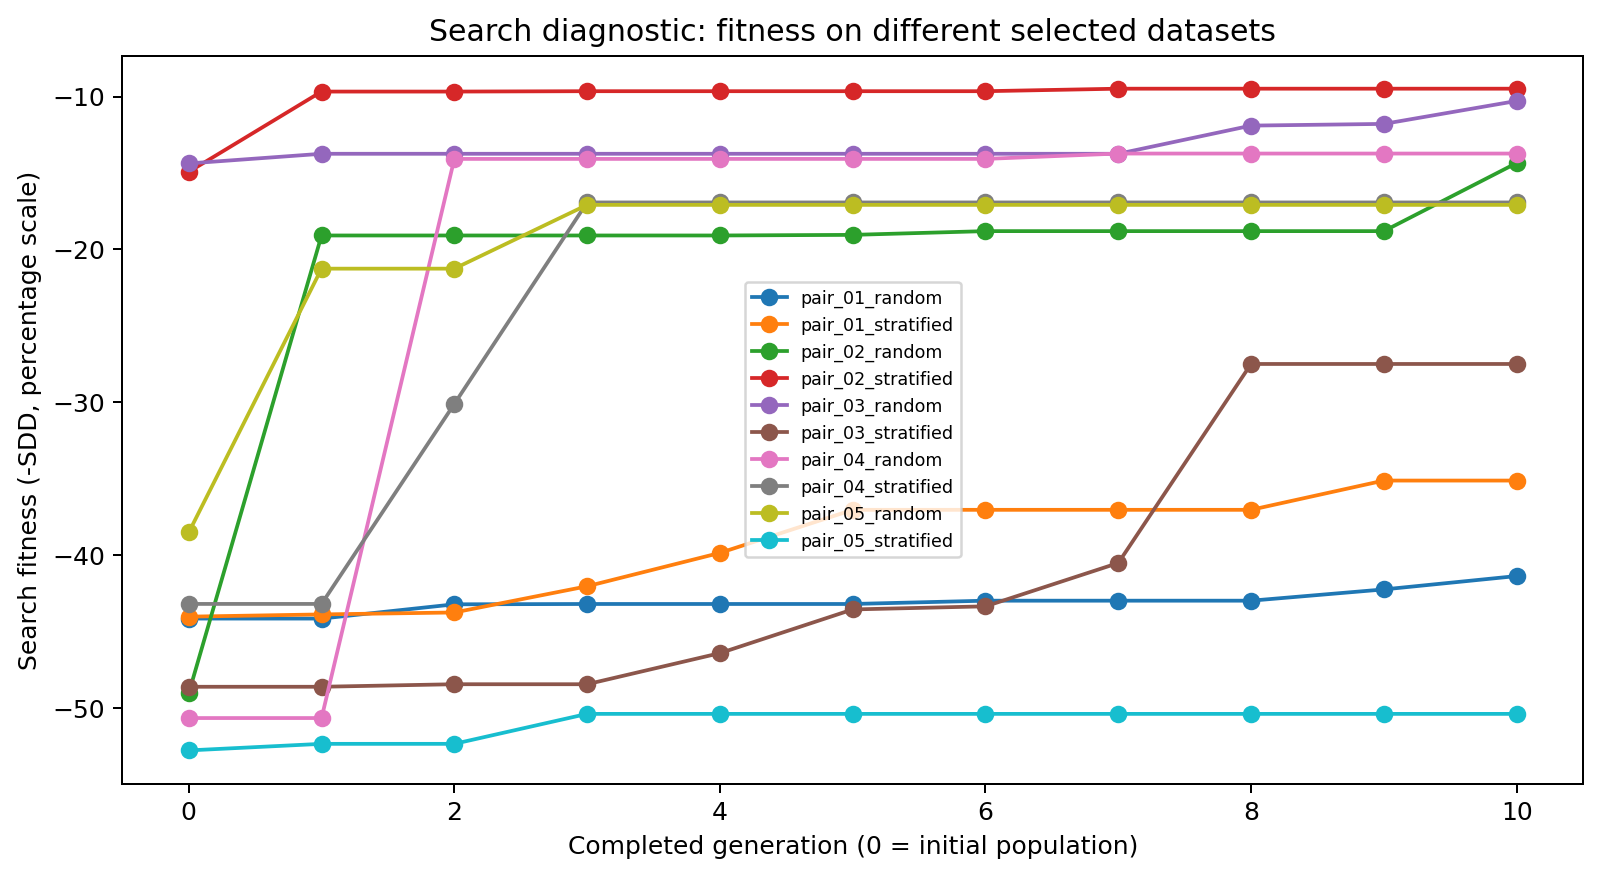

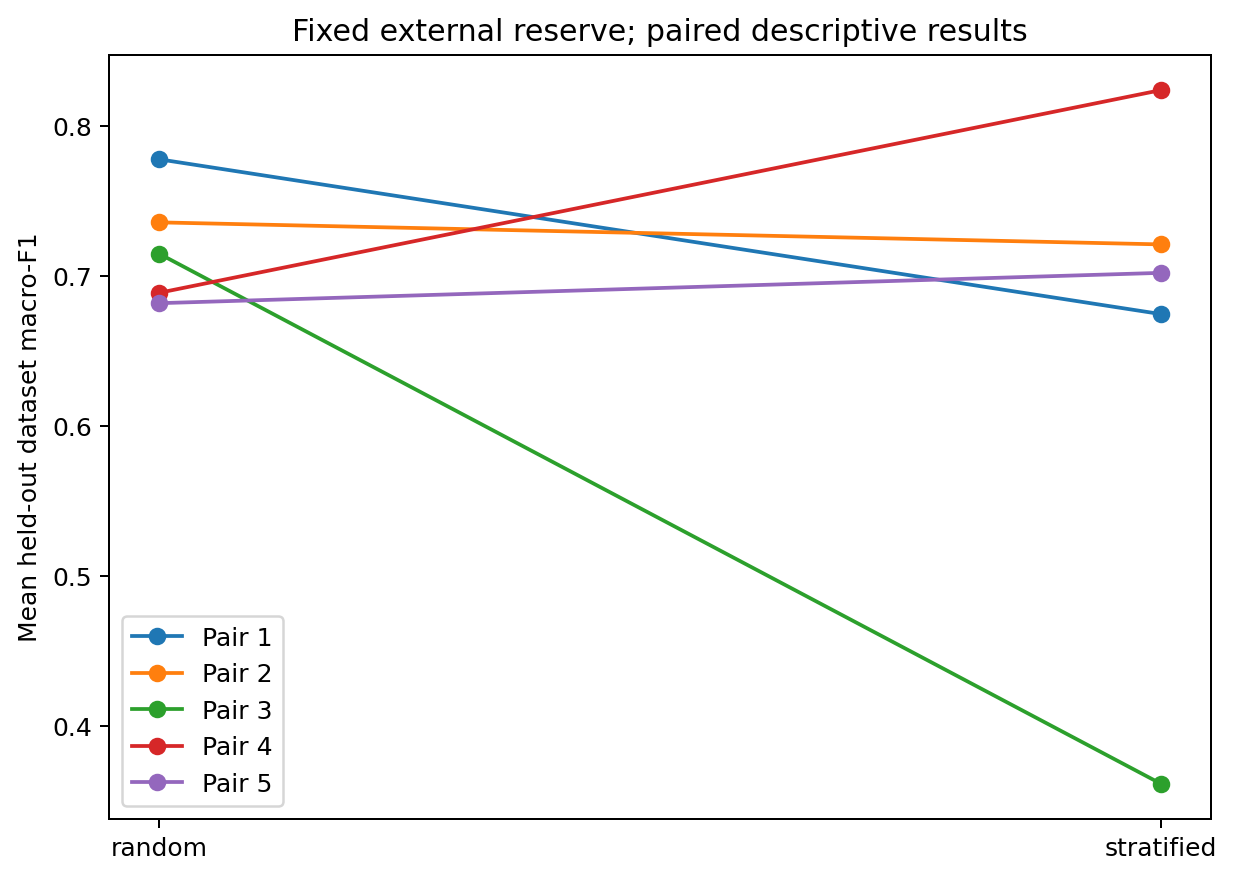

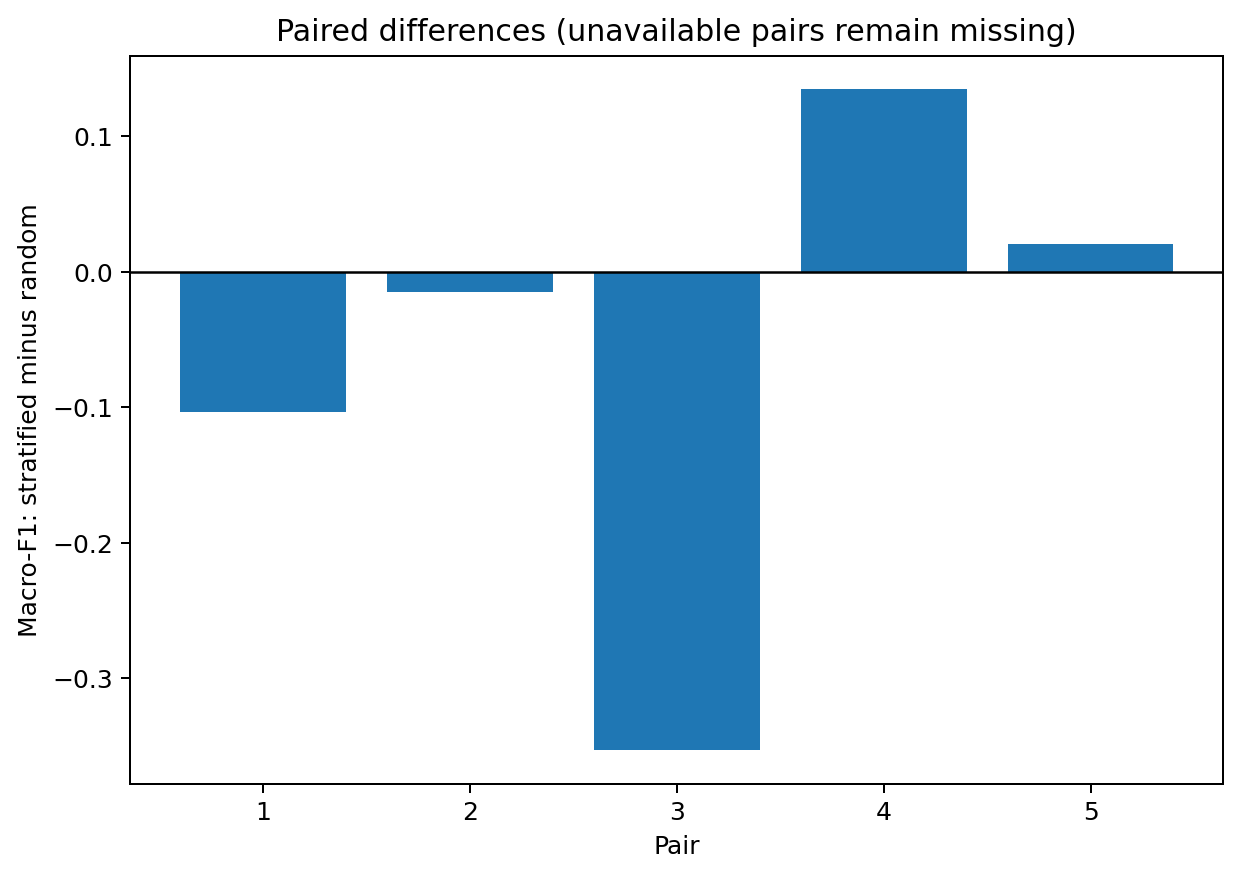

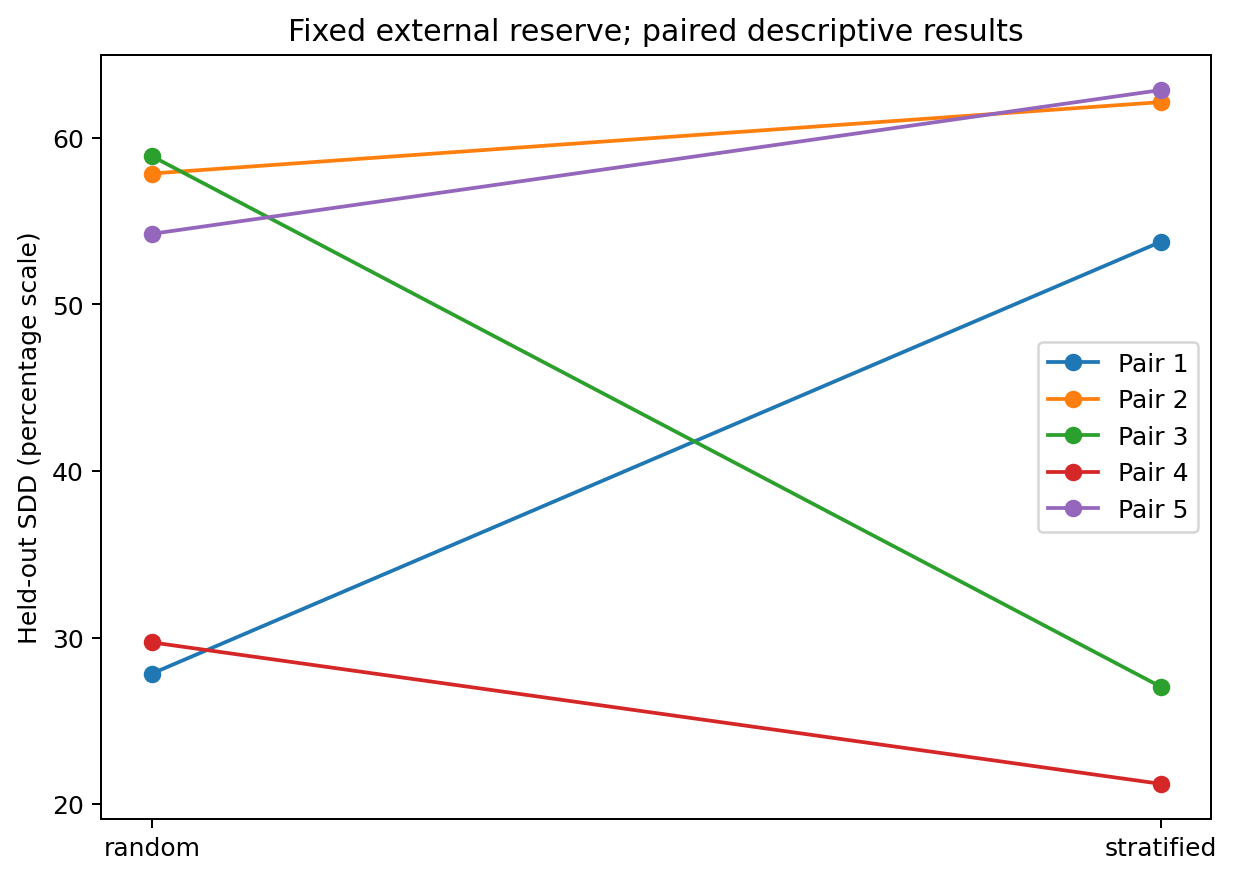

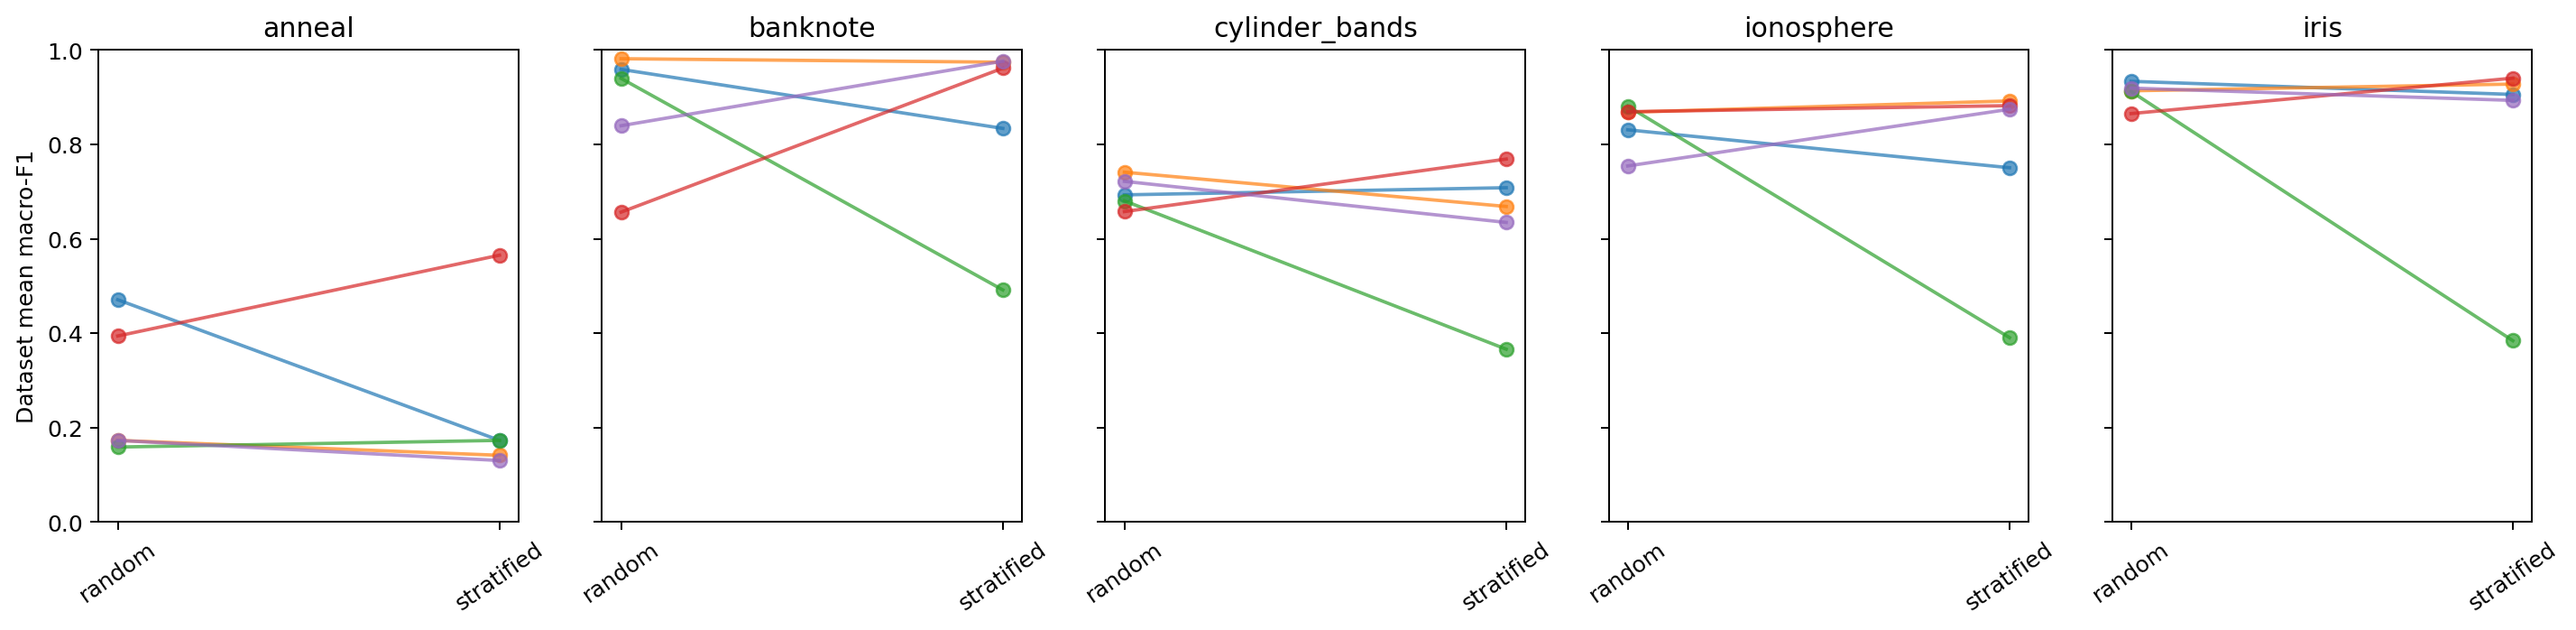

Result directory: c:\Users\sarah\OneDrive\Documentos\DCC_Thesis_codes\AutoML_DecisionTrees\results\random_vs_stratified_sdd


In [27]:
if (RESULTS / "search_histories.csv").exists():
    display(pd.read_csv(RESULTS / "search_histories.csv"))
for stem in ["search_fitness_diagnostic", "final_macro_f1", "paired_macro_f1_differences", "final_sdd", "held_out_dataset_results"]:
    file = RESULTS / "figures" / (stem + ".png")
    if file.exists():
        display(Image(filename=str(file)))
print("Result directory:", RESULTS)